## **Task 01- Exploratory Data Analysis (EDA) on Superstore Retail Sales**

**Goal:** Perform data wrangling, missing-value profiling, and uncover commercial sales distributions.

## **Executive Summary**

1. **Discounts above 20% lose money.** Margin is 29.5% with no discount and negative in every band above 20%.
2. **Tables and Bookcases drag Furniture down.** Furniture is about 32% of sales but only about 6% of profit.
3. **Top customers are not always profitable.** The #1 customer by sales has a negative profit, and 19.5% of customers lose money.
4. **Sales are seasonal.** September, November and December give about 43% of a typical year's sales.
5. **Sales grow faster than profit.** In 2018, sales grew 20.4% but profit only 14.2%.

Evidence and recommendations for each finding are in the *Executive Takeaways* section at the end of this notebook.

 **Load and First Look at the Data**

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = "{:,.2f}".format

df = pd.read_csv("superstore_sales.csv")
print(df.shape)
df.head()

(10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2.00,0.00,41.91
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,"42,420.00",South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3.00,0.00,219.58
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,"90,036.00",West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2.00,0.00,6.87
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5.00,0.45,-383.03
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,"33,311.00",South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2.00,0.20,2.52


**NOTE**

**What this shows:** The raw file has 10,800 rows and 21 columns. Each row is one product line in an order, with order and ship dates, customer details, region, product category, and the numbers Sales, Quantity, Discount and Profit.

**What I noticed:** The dates are stored as text, and some columns show decimals (like Quantity `2.00` and Postal Code `42,420.00`) that should be whole numbers or text codes. I fix these in the cleaning step.

**Structure and Data Quality**

In [66]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

**NOTE**

**What this shows:** `df.info()` lists every column, how many values are filled in, and the data type. The file has 10,800 rows, but most columns have only 9,994 filled values, so 806 rows are missing almost everything. Postal Code has 9,983 filled values, so it has 11 more gaps on top of that.

**Data type problems:**
- `Row ID` is stored as text (`object`) but should be a number.
- `Order Date` and `Ship Date` are text, not real dates.
- `Quantity` is a decimal (`float64`) but should be a whole number.
- `Postal Code` is a decimal, but a postal code is an identifier and should be text.

**What I do next:** I investigate the 806 incomplete rows before deciding how to handle them, and I fix the data types in the cleaning step.

In [67]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,"9,983.00","9,994.00","9,994.00","9,994.00","9,994.00"
mean,"55,245.23",229.86,3.79,0.16,28.66
std,"32,038.72",623.25,2.23,0.21,234.26
min,"1,040.00",0.44,1.00,0.00,"-6,599.98"
25%,"23,223.00",17.28,2.00,0.00,1.73
50%,"57,103.00",54.49,3.00,0.20,8.67
75%,"90,008.00",209.94,5.00,0.20,29.36
max,"99,301.00","22,638.48",14.00,0.80,"8,399.98"


In [68]:
# Missing values: count and percentage
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().sum() / len(df) * 100).round(2)
})
missing[missing.missing_count > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_pct
Postal Code,817,7.56
Ship Date,806,7.46
Order Date,806,7.46
Ship Mode,806,7.46
Customer ID,806,7.46
Segment,806,7.46
Customer Name,806,7.46
Country,806,7.46
City,806,7.46
State,806,7.46


**NOTE**

**What this shows:** 18 columns are missing exactly 806 values (7.46%), and Postal Code is missing 817 (7.56%).

**What I noticed:** The identical count means the same 806 rows are empty, not scattered gaps. Postal Code has 11 extra missing values. I investigate both next.

In [69]:
# Duplicates
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate Row IDs:", df["Row ID"].duplicated().sum())

Fully duplicated rows: 504
Duplicate Row IDs: 799


**NOTE**

**What this shows:** 504 fully duplicated rows and 799 repeated Row IDs.

**What I noticed:** Real order rows should have a unique Row ID, so this is not normal duplication. I check the blank rows before removing anything, because they may be causing it.

In [70]:
# A. Look at the blank rows
blank = df[df["Order Date"].isnull()]
print(len(blank))
blank.head(10)

806


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9994,Person,Region,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9996,Chuck Magee,East,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9999,Returned,Order ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10002,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10003,Yes,CA-2015-100762,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**NOTE**

**What this shows:** The 806 incomplete rows are not sales. They hold only two columns of text: names with regions (`Anna Andreadi | West`) and the word `Yes` with order IDs (`CA-2015-100762`).

**Finding:** The CSV contains three tables stacked together: Orders (9,994 rows), People (4 regional managers) and Returns (800 rows). This explains the missing values, the text `Row ID` and the repeated IDs found above.

**Next:** I split them into separate tables so the Orders data is clean.

In [71]:
# B. Confirm they are blank in every column except the two ID columns
core_cols = [c for c in df.columns if c not in ["Row ID", "Order ID"]]
print("Rows empty in all other columns:", df[core_cols].isnull().all(axis=1).sum())

Rows empty in all other columns: 806


**NOTE**

**What this shows:** All 806 incomplete rows are empty in every column except the two ID columns, so they are not real sales rows.

In [72]:
# C. The 11 real rows with missing Postal Code
df[df["Postal Code"].isnull() & df["Order Date"].notnull()][["City", "State", "Postal Code"]].drop_duplicates()

,City,State,Postal Code
2234,Burlington,Vermont,NaN


**NOTE**

**What this shows:** The 11 other missing Postal Codes are all for one city, Burlington, Vermont. I handle them in the cleaning step.

In [73]:
# D. What is odd about Row ID?
df["Row ID"].tail(10)

,Row ID
10790,Yes
10791,Yes
10792,Yes
10793,Yes
10794,Yes
10795,Yes
10796,Yes
10797,Yes
10798,Yes
10799,Yes


**NOTE**

**What this shows:** The end of `Row ID` contains the word `Yes` instead of numbers. This is why the column was stored as text.

# **DATA CLEANING**

In [74]:
# 1. Split the stacked sheets
orders = df[df["Order Date"].notnull()].copy()
extra  = df[df["Order Date"].isnull()].copy()

people = extra.iloc[1:5, :2].copy()
people.columns = ["Person", "Region"]
people = people.reset_index(drop=True)

returns = extra.iloc[6:, :2].copy()
returns.columns = ["Returned", "Order ID"]
returns = returns.reset_index(drop=True)

print(orders.shape, people.shape, returns.shape)
people

(9994, 21) (4, 2) (800, 2)


,Person,Region
0,Anna Andreadi,West
1,Chuck Magee,East
2,Kelly Williams,Central
3,Cassandra Brandow,South


**NOTE**
**What this shows:** The file is now split into three tables: Orders (9,994 rows, 21 columns), People (4 regional managers) and Returns (800 rows).

**Decision:** I keep only `orders` for the sales analysis. People and Returns are stored separately and are not part of it.


In [75]:
# 2. Fix data types on the orders table
orders["Row ID"]   = orders["Row ID"].astype(int)
orders["Quantity"] = orders["Quantity"].astype(int)

# Postal code: fill Burlington, VT, then store as 5-digit text
orders.loc[orders["Postal Code"].isnull(), "Postal Code"] = 5401
orders["Postal Code"] = orders["Postal Code"].astype(int).astype(str).str.zfill(5)

**NOTE**

**What I did:**
- Converted `Row ID` and `Quantity` to whole numbers.
- Filled the 11 missing Postal Codes (all Burlington, Vermont) with 05401, the city's main ZIP code, from public information. This is an assumption, and it does not affect the sales analysis.
- Stored Postal Code as 5-digit text, because it is an identifier, not a quantity, and some codes start with zero.

In [76]:
# 3. Verify the result
print("Missing values left:", orders.isnull().sum().sum())
print("Duplicate rows:", orders.duplicated().sum())
print("Duplicate Row IDs:", orders["Row ID"].duplicated().sum())
print("Unique returned orders:", returns["Order ID"].nunique(), "of", len(returns), "rows")
orders[["Row ID", "Quantity", "Postal Code"]].dtypes

Missing values left: 0
Duplicate rows: 0
Duplicate Row IDs: 0
Unique returned orders: 296 of 800 rows


,0
Row ID,int64
Quantity,int64
Postal Code,object


**NOTE**

**What this shows:** The Orders table now has no missing values, no duplicate rows and no duplicate Row IDs, and the data types are correct.

**About the earlier duplicates:** The 504 "duplicate" rows came from the Returns sheet, where one order appears several times. 800 rows - 296 unique returned orders = 504.

In [77]:
# What postal codes does Burlington use elsewhere in the dataset?
df[df["City"] == "Burlington"][["City", "State", "Postal Code"]].drop_duplicates()

,City,State,Postal Code
683,Burlington,North Carolina,"27,217.00"
1008,Burlington,Iowa,"52,601.00"
2234,Burlington,Vermont,NaN


**NOTE**

**What this shows:** The other two Burlingtons in the data are in North Carolina and Iowa, so their postal codes can't be used for Vermont. Vermont has no postal code anywhere in the file, so I fill it from public information (05401).

In [78]:
# Convert text dates to real dates (format is month/day/year)
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y")
orders["Ship Date"]  = pd.to_datetime(orders["Ship Date"],  format="%m/%d/%Y")

# Extract time features
orders["Year"]       = orders["Order Date"].dt.year
orders["Month"]      = orders["Order Date"].dt.month
orders["Year-Month"] = orders["Order Date"].dt.to_period("M").astype(str)

# Sanity checks
print("Earliest order:", orders["Order Date"].min())
print("Latest order:  ", orders["Order Date"].max())
print("Shipped before ordered:", (orders["Ship Date"] < orders["Order Date"]).sum())
orders[["Order Date", "Year", "Month", "Year-Month"]].head()

Earliest order: 2015-01-03 00:00:00
Latest order:   2018-12-30 00:00:00
Shipped before ordered: 0


,Order Date,Year,Month,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


**NOTE**

**What I did:** Converted `Order Date` and `Ship Date` from text to real dates (month/day/year format) and created `Year`, `Month` and `Year-Month` columns.

**Checks:** Orders run from 3 Jan 2015 to 30 Dec 2018 (48 months), and no order shipped before it was placed.

In [79]:
# Safety check: how many months do we have?
print("Months in data:", orders["Year-Month"].nunique())

Months in data: 48


**NOTE**

**What this shows:** The data covers 48 months (2015-2018), so every calendar month appears four times.

In [80]:
# Summary by Category
cat_summary = orders.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

cat_summary["Profit_Margin_%"] = (cat_summary["Total_Profit"] / cat_summary["Total_Sales"] * 100).round(2)
cat_summary.sort_values("Total_Sales", ascending=False)

,Category,Total_Sales,Total_Profit,Orders,Profit_Margin_%
2,Technology,"836,154.03","145,454.95",1544,17.40
0,Furniture,"741,999.80","18,451.27",1764,2.49
1,Office Supplies,"719,047.03","122,490.80",3742,17.04


**What this shows:** Technology has the highest sales (836K) and the best margin (17.4%). Office Supplies has a similar margin (17.0%). Furniture sells almost as much as Technology (742K) but earns only a 2.49% margin (18K profit).

**Note:** The Orders column counts distinct orders. One order can contain several categories, so these counts add up to more than the true number of orders.

In [81]:
# Summary by Region
reg_summary = orders.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

reg_summary["Profit_Margin_%"] = (reg_summary["Total_Profit"] / reg_summary["Total_Sales"] * 100).round(2)
reg_summary.sort_values("Total_Sales", ascending=False)

,Region,Total_Sales,Total_Profit,Orders,Profit_Margin_%
3,West,"725,457.82","108,418.45",1611,14.94
1,East,"678,781.24","91,522.78",1401,13.48
0,Central,"501,239.89","39,706.36",1175,7.92
2,South,"391,721.91","46,749.43",822,11.93


**NOTE**

**What this shows:** West leads in both sales (725K) and margin (14.9%). Central has higher sales than South (501K vs 392K) but earns less profit (39.7K vs 46.7K), so its margin is the weakest at 7.9%.

In [82]:
# Summary by Segment
seg_summary = orders.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).reset_index()

seg_summary["Profit_Margin_%"] = (seg_summary["Total_Profit"] / seg_summary["Total_Sales"] * 100).round(2)
seg_summary.sort_values("Total_Sales", ascending=False)

,Segment,Total_Sales,Total_Profit,Orders,Profit_Margin_%
0,Consumer,"1,161,401.34","134,119.21",2586,11.55
1,Corporate,"706,146.37","91,979.13",1514,13.03
2,Home Office,"429,653.15","60,298.68",909,14.03


**NOTE**

**What this shows:** Consumer is the largest segment (1.16M in sales) but has the lowest margin (11.6%). Home Office is the smallest (430K) but has the highest margin (14.0%).

**Find out why Furniture is weak**

In [83]:
# Sub-Category performance
sub_summary = orders.groupby(["Category", "Sub-Category"]).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

sub_summary["Profit_Margin_%"] = (sub_summary["Total_Profit"] / sub_summary["Total_Sales"] * 100).round(2)
sub_summary.sort_values("Total_Profit")

,Category,Sub-Category,Total_Sales,Total_Profit,Profit_Margin_%
3,Furniture,Tables,"206,965.53","-17,725.48",-8.56
0,Furniture,Bookcases,"114,880.00","-3,472.56",-3.02
12,Office Supplies,Supplies,"46,673.54","-1,189.10",-2.55
8,Office Supplies,Fasteners,"3,024.28",949.52,31.40
15,Technology,Machines,"189,238.63","3,384.76",1.79
9,Office Supplies,Labels,"12,486.31","5,546.25",44.42
5,Office Supplies,Art,"27,118.79","6,527.79",24.07
7,Office Supplies,Envelopes,"16,476.40","6,964.18",42.27
2,Furniture,Furnishings,"91,705.16","13,059.14",14.24
4,Office Supplies,Appliances,"107,532.16","18,138.01",16.87


**NOTE**

**What this shows:** Three sub-categories lose money: Tables (-17.7K), Bookcases (-3.5K) and Supplies (-1.2K). Machines sells a lot (189K) but earns almost nothing (3.4K, 1.8% margin). The biggest profit comes from Copiers (55.6K), Phones (44.5K) and Accessories (41.9K).

**What I noticed:** The Furniture weakness comes from Tables and Bookcases, not the whole category. Chairs (+26.6K) and Furnishings (+13.1K) are profitable. I check discounts as a possible reason later.

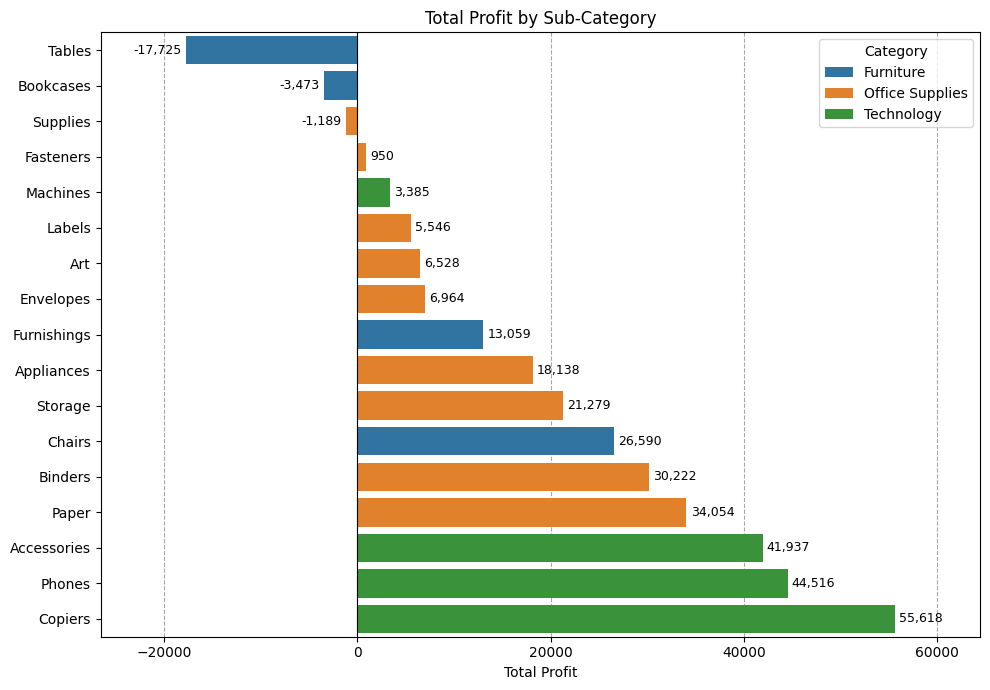

In [84]:
# Chart: profit by Sub-Category
import os
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(10, 7))
order = sub_summary.sort_values("Total_Profit")["Sub-Category"]
ax = sns.barplot(data=sub_summary, y="Sub-Category", x="Total_Profit", order=order, hue="Category", dodge=False)
plt.axvline(0, color="black", linewidth=0.8)
for c in ax.containers: ax.bar_label(c, labels=[f"{v:,.0f}" if abs(v) > 0 else "" for v in c.datavalues], padding=3, fontsize=9)
ax.margins(x=0.12)
ax.grid(axis="x", color="gray", linestyle="--", alpha=0.7)
ax.set_axisbelow(True)
plt.title("Total Profit by Sub-Category")
plt.xlabel("Total Profit")
plt.ylabel("")
plt.tight_layout()
plt.savefig("charts/01_profit_by_subcategory.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Profit by sub-category, with the zero line marking break-even. Tables, Bookcases and Supplies fall to the left of zero, so they lose money. Copiers, Phones and Accessories earn the most.

In [85]:
# Average discount by sub-category
disc = orders.groupby("Sub-Category").agg(
    Avg_Discount=("Discount", "mean"),
    Total_Profit=("Profit", "sum")
).reset_index()
disc["Avg_Discount_%"] = (disc["Avg_Discount"] * 100).round(1)
disc.sort_values("Avg_Discount_%", ascending=False)

,Sub-Category,Avg_Discount,Total_Profit,Avg_Discount_%
3,Binders,0.37,"30,221.76",37.20
11,Machines,0.31,"3,384.76",30.60
16,Tables,0.26,"-17,725.48",26.10
4,Bookcases,0.21,"-3,472.56",21.10
5,Chairs,0.17,"26,590.17",17.00
1,Appliances,0.17,"18,138.01",16.70
6,Copiers,0.16,"55,617.82",16.20
13,Phones,0.15,"44,515.73",15.50
9,Furnishings,0.14,"13,059.14",13.80
8,Fasteners,0.08,949.52,8.20


**NOTE**

**What this shows:** Average discount for each sub-category, next to its total profit.

**What I noticed:** Machines (30.6%), Tables (26.1%) and Bookcases (21.1%) have high average discounts and weak or negative profit. Two exceptions: Binders has the highest discount (37.2%) but is still profitable, and Supplies loses money with a low discount (7.7%). So discounts do not explain every result.

In [86]:
# Table: profit at each discount level
tables = orders[orders["Sub-Category"] == "Tables"]
tables.groupby("Discount").agg(
    Rows=("Row ID", "count"),
    Total_Profit=("Profit", "sum")
).reset_index()

,Discount,Rows,Total_Profit
0,0.00,72,"13,276.30"
1,0.20,71,-303.56
2,0.30,54,"-3,402.33"
3,0.40,75,"-16,187.40"
4,0.45,11,"-2,493.11"
5,0.50,36,"-8,615.39"


**NOTE**

**What this shows:** Total profit on Tables at each discount level.

**What I noticed:** With no discount, Tables earn +13.3K. At 20% they roughly break even (-0.3K). At every level from 30% upward they lose money, and the 176 rows sold at 30% or more lost about 30.7K together. This is more than the whole Tables loss of 17.7K, so Tables are profitable when the discount is kept low.

In [87]:
# Create discount bands
bins   = [-0.01, 0, 0.10, 0.20, 0.30, 0.40, 0.50, 0.80]
labels = ["0%", "1-10%", "11-20%", "21-30%", "31-40%", "41-50%", "51-80%"]
orders["Discount_Band"] = pd.cut(orders["Discount"], bins=bins, labels=labels)

band = orders.groupby("Discount_Band", observed=True).agg(
    Rows=("Row ID", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Avg_Profit=("Profit", "mean")
).reset_index()
band["Profit_Margin_%"] = (band["Total_Profit"] / band["Total_Sales"] * 100).round(2)
band

,Discount_Band,Rows,Total_Sales,Total_Profit,Avg_Profit,Profit_Margin_%
0,0%,4798,"1,087,908.47","320,987.60",66.90,29.51
1,1-10%,94,"54,369.35","9,029.18",96.06,16.61
2,11-20%,3709,"792,152.89","91,756.30",24.74,11.58
3,21-30%,227,"103,226.65","-10,369.28",-45.68,-10.05
4,31-40%,233,"130,911.24","-25,448.19",-109.22,-19.44
5,41-50%,77,"64,403.51","-22,999.54",-298.70,-35.71
6,51-80%,856,"64,228.74","-76,559.05",-89.44,-119.20


**NOTE**

**What this shows:** Sales, profit and profit margin for each discount band.

**What I noticed:** The margin falls with every step up in discount. It is 29.5% with no discount and 11.6% at 11-20%. Every band above 20% loses money, from -10% to -119%. These bands cover 1,393 order lines and lost about 135K in total, while the lines at 20% or less earned about 422K. The 51-80% band is the worst: it brought in only 64K in sales but lost 76.6K.

**Caution:** This shows that heavy discounts and losses go together. The data has no cost column, so it cannot prove that discounts cause the losses.

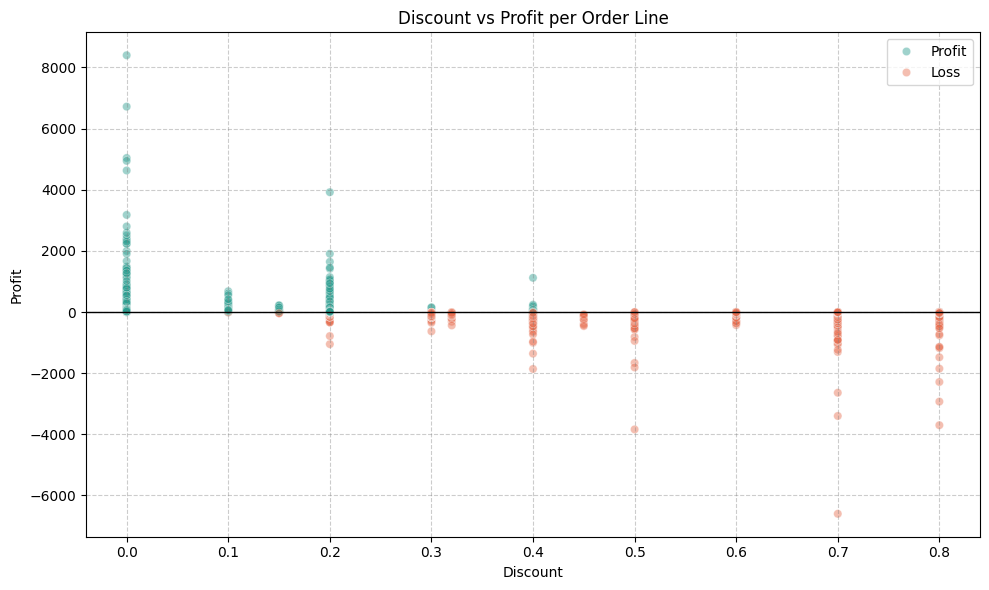

In [88]:
# Scatter plot: Discount vs Profit
import os
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(10, 6))
result = (orders["Profit"] >= 0).map({True: "Profit", False: "Loss"})
sns.scatterplot(data=orders, x="Discount", y="Profit", alpha=0.45, hue=result,
                hue_order=["Profit", "Loss"], palette={"Profit": "#2A9D8F", "Loss": "#E76F51"})
plt.axhline(0, color="black", linewidth=1)
plt.grid(color="gray", linestyle="--", alpha=0.4)
plt.legend(loc="upper right", title="")
plt.title("Discount vs Profit per Order Line")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()
plt.savefig("charts/02_discount_vs_profit.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Each dot is one order line. The dots form vertical stripes because discounts come in fixed levels (0, 0.1, 0.2 and so on).

**What I noticed:** The biggest profits are at 0% discount. From 30% upward almost every dot is at or below zero, and the largest single loss (about -6,600) is at a 70% discount.

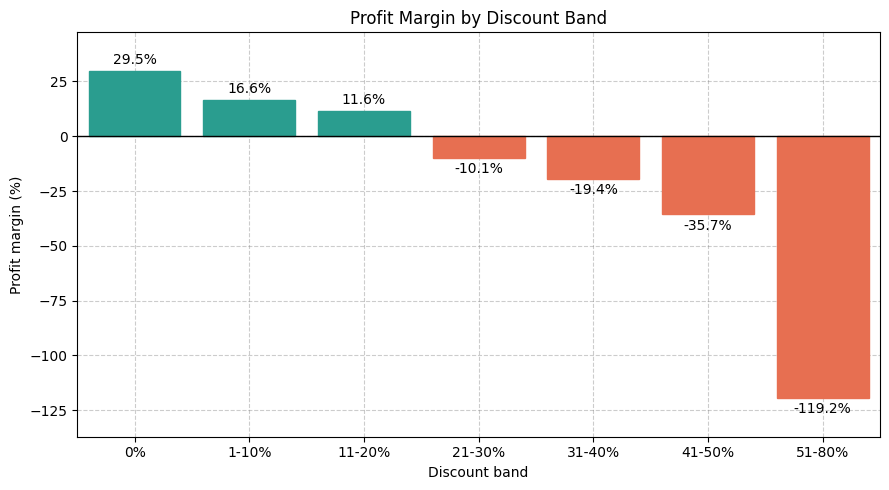

In [89]:
# Bar chart: profit margin by discount band
import os
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(9, 5))
ax = sns.barplot(data=band, x="Discount_Band", y="Profit_Margin_%", color="steelblue")
for bar, v in zip(ax.patches, band["Profit_Margin_%"]):
    bar.set_color("#2A9D8F" if v >= 0 else "#E76F51")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.margins(y=0.12)
ax.grid(axis="both", color="gray", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.axhline(0, color="black", linewidth=1)
plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount band")
plt.ylabel("Profit margin (%)")
plt.tight_layout()
plt.savefig("charts/03_margin_by_discount_band.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Profit margin for each discount band. The margin falls with every step up in discount and turns negative above 20%.

**What I noticed:** Margin is +29.5% with no discount and -119.2% in the 51-80% band. The 21-30% band is the first to lose money.

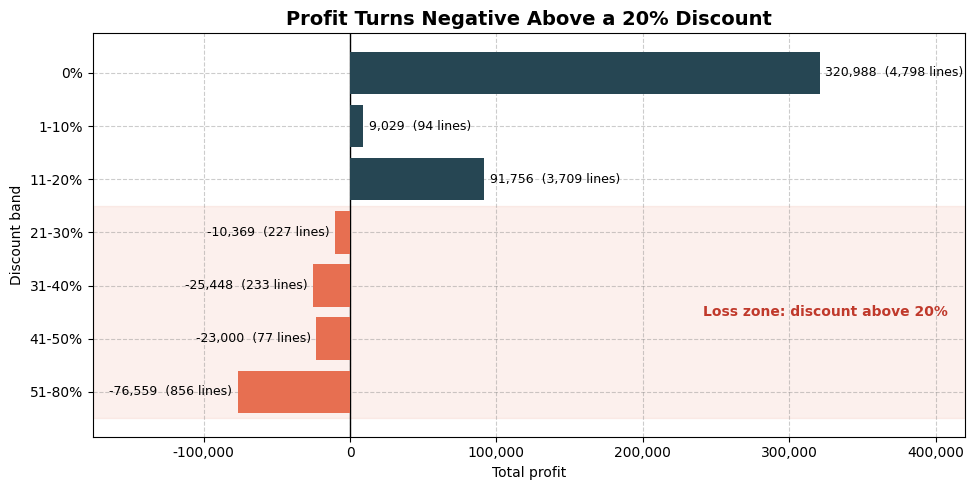

In [90]:
# Chart: total profit by discount band (horizontal, with loss zone)
import os
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(10, 5))
ax = plt.gca()
colors = ["#264653" if v >= 0 else "#E76F51" for v in band["Total_Profit"]]
bars = ax.barh(band["Discount_Band"], band["Total_Profit"], color=colors, zorder=3)
ax.invert_yaxis()
ax.bar_label(bars, labels=[f"{p:,.0f}  ({r:,} lines)" for p, r in zip(band["Total_Profit"], band["Rows"])], padding=4, fontsize=9)
ax.axhspan(2.5, 6.5, color="#E76F51", alpha=0.10)
ax.text(0.98, 4.5, "Loss zone: discount above 20%", transform=ax.get_yaxis_transform(),
        ha="right", va="center", color="#C0392B", fontweight="bold")
ax.axvline(0, color="black", linewidth=1)
ax.grid(axis="both", color="gray", linestyle="--", alpha=0.4, zorder=0)
ax.margins(x=0.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
plt.title("Profit Turns Negative Above a 20% Discount", fontsize=14, fontweight="bold")
plt.xlabel("Total profit")
plt.ylabel("Discount band")
plt.tight_layout()
plt.savefig("charts/03b_profit_by_discount_band.png", dpi=150, bbox_inches="tight")
plt.show()

**Insight:** Profit stays positive up to a 20% discount and turns negative above it: the 1,393 lines above 20% lost about 135K, and the 51-80% band alone lost 76.6K.

In [91]:
# Per-customer summary
cust = orders.groupby(["Customer ID", "Customer Name"]).agg(
    Orders=("Order ID", "nunique"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()
cust["Avg_Order_Value"] = (cust["Total_Sales"] / cust["Orders"]).round(2)

print("Unique customers:", len(cust))
cust.describe()

Unique customers: 793


,Orders,Total_Sales,Total_Profit,Avg_Order_Value
count,793.00,793.00,793.00,793.00
mean,6.32,"2,896.85",361.16,460.15
std,2.55,"2,628.67",894.26,433.40
min,1.00,4.83,"-6,626.39",2.42
25%,5.00,"1,146.05",36.61,213.26
50%,6.00,"2,256.39",227.83,362.50
75%,8.00,"3,785.28",560.01,550.38
max,17.00,"25,043.05","8,981.32","5,008.61"


**NOTE**

**What this shows:** A summary of the 793 customers: orders placed, total sales, total profit and average order value.

**What I noticed:** A typical customer placed about 6 orders over the four years (median 6) and spent about 2,300 (median 2,256). The average spend is higher (2,897) because a few large customers pull it up. The best customer spent 25,043, and the weakest customer lost 6,626 for the company.

In [92]:
# Top 10 customers by sales
top10 = cust.sort_values("Total_Sales", ascending=False).head(10)
top10

,Customer ID,Customer Name,Orders,Total_Sales,Total_Profit,Avg_Order_Value
700,SM-20320,Sean Miller,5,"25,043.05","-1,980.74","5,008.61"
741,TC-20980,Tamara Chand,5,"19,052.22","8,981.32","3,810.44"
621,RB-19360,Raymond Buch,6,"15,117.34","6,976.10","2,519.56"
730,TA-21385,Tom Ashbrook,4,"14,595.62","4,703.79","3,648.90"
6,AB-10105,Adrian Barton,10,"14,473.57","5,444.81","1,447.36"
434,KL-16645,Ken Lonsdale,12,"14,175.23",806.86,"1,181.27"
669,SC-20095,Sanjit Chand,9,"14,142.33","5,757.41","1,571.37"
327,HL-15040,Hunter Lopez,6,"12,873.30","5,622.43","2,145.55"
683,SE-20110,Sanjit Engle,11,"12,209.44","2,650.68","1,109.95"
131,CC-12370,Christopher Conant,5,"12,129.07","2,177.05","2,425.81"


**NOTE**

**What this shows:** The 10 customers with the highest total sales, from 12K to 25K each.

**What I noticed:** Big sales do not always mean big profit. The top customer, Sean Miller, has a profit of -1,981, and Ken Lonsdale (12 orders, 14.2K in sales) earns only 807. Tamara Chand is the strongest: 19.1K in sales and 9.0K in profit.

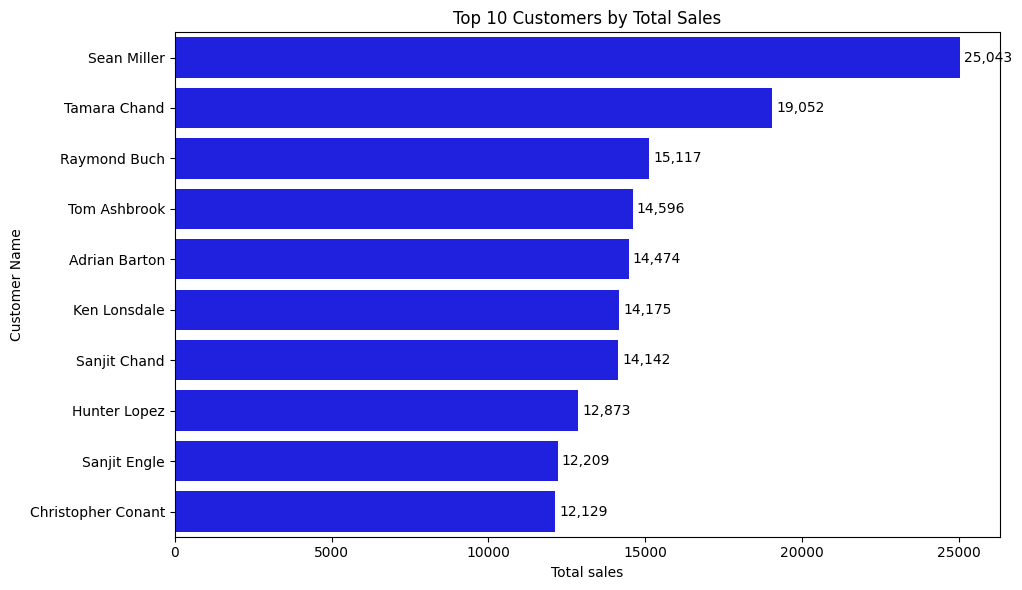

In [93]:
# Chart: top 10 customers
plt.figure(figsize=(10, 6))
sns.barplot(data=top10, y="Customer Name", x="Total_Sales", color="steelblue")
plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Total sales")
plt.ylabel("")
plt.tight_layout()
ax = sns.barplot(data=top10, y="Customer Name", x="Total_Sales", color="blue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
plt.savefig("charts/04_top10_customers.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Total sales for the top 10 customers, with the value printed on each bar. Sean Miller is clearly first (25,043), followed by Tamara Chand (19,052). The other eight are close together, between 12K and 15K.

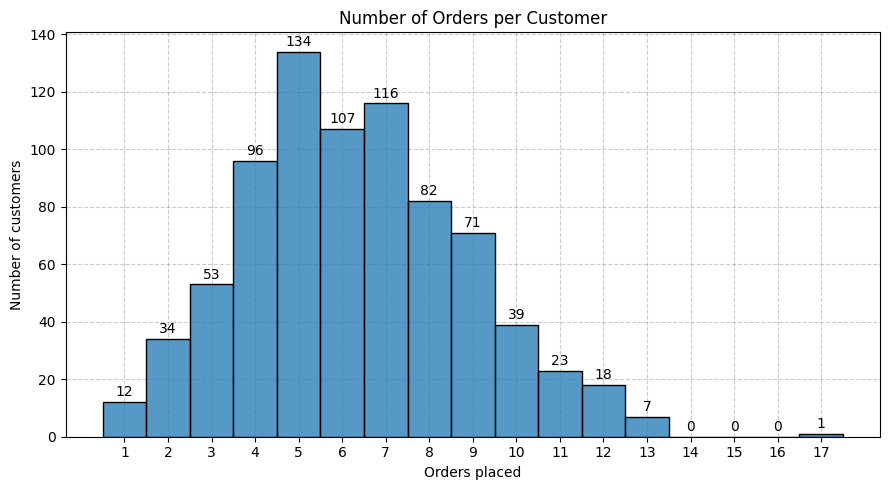

In [94]:
# Chart: how many orders does a typical customer place?
plt.figure(figsize=(9, 5))
ax = sns.histplot(data=cust, x="Orders", discrete=True)
ax.set_xticks(range(1, int(cust["Orders"].max()) + 1))
ax.bar_label(ax.containers[0], padding=2)
ax.grid(axis="both", color="gray", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.title("Number of Orders per Customer")
plt.xlabel("Orders placed")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.savefig("charts/05_orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** How many customers placed each number of orders. Most customers placed between 4 and 8 orders, and the most common is 5 orders (134 customers).

**What I noticed:** Only 12 customers ordered once, so most customers come back. Very few place more than 12 orders, and the maximum is 17 (one customer).

In [95]:
# How concentrated is revenue?
cust_sorted = cust.sort_values("Total_Sales", ascending=False)
top_n = int(len(cust_sorted) * 0.10)
share = cust_sorted.head(top_n)["Total_Sales"].sum() / cust_sorted["Total_Sales"].sum() * 100
print(f"Top 10% of customers ({top_n} customers) generate {share:.1f}% of sales")

Top 10% of customers (79 customers) generate 30.6% of sales


**NOTE**

**What this shows:** The top 10% of customers (79 people) generate 30.6% of total sales.

**What I noticed:** Revenue is spread across many customers, and it does not depend on a small group. Losing a few top customers would not threaten the business.

**why does the top customer lose money?**

In [96]:
# Sean Miller buying, and at what discount?
sean = orders[orders["Customer Name"] == "Sean Miller"]
sean.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean")
).sort_values("Profit")

,Sales,Profit,Avg_Discount
Sub-Category,,,
Machines,"23,459.78","-1,827.50",0.50
Storage,663.07,-165.77,0.20
Binders,99.59,-82.99,0.70
Supplies,3.49,-0.70,0.20
Art,8.02,1.00,0.20
Accessories,21.73,3.80,0.20
Fasteners,18.94,5.92,0.20
Paper,88.87,30.54,0.15
Furnishings,679.57,54.96,0.13


**NOTE**

**What this shows:** What the top customer, Sean Miller, bought, with profit and average discount for each sub-category.

**What I noticed:** Almost all of his loss comes from Machines: 23,460 in sales, -1,828 in profit, at a 50% average discount. This is about 92% of his total loss (-1,981). His other purchases are small.


In [97]:
# customers lose money overall
loss_customers = cust[cust["Total_Profit"] < 0]
print(len(loss_customers), "customers lose money =", round(len(loss_customers) / len(cust) * 100, 1), "% of customers")
print("Total loss from them:", round(loss_customers["Total_Profit"].sum(), 2))

155 customers lose money = 19.5 % of customers
Total loss from them: -71224.47


**NOTE**

**What this shows:** 155 customers (19.5%) lose money for the company, with a combined loss of 71,224.

**What I noticed:** About 1 customer in 5 is unprofitable. Their loss equals about 25% of the company's total profit (286K). Sean Miller's case suggests heavy discounts may be involved, but I did not test this for every customer.

**Monthly seasonality**

In [98]:
# Yearly totals (is the business growing?)
yearly = orders.groupby("Year").agg(Total_Sales=("Sales", "sum"), Total_Profit=("Profit", "sum")).reset_index()
yearly["Margin_%"] = (yearly["Total_Profit"] / yearly["Total_Sales"] * 100).round(2)
yearly["Sales_Growth_%"] = (yearly["Total_Sales"].pct_change() * 100).round(1)
yearly

,Year,Total_Sales,Total_Profit,Margin_%,Sales_Growth_%
0,2015,"484,247.50","49,543.97",10.23,NaN
1,2016,"470,532.51","61,618.60",13.10,-2.80
2,2017,"609,205.60","81,795.17",13.43,29.50
3,2018,"733,215.26","93,439.27",12.74,20.40


**NOTE**

**What this shows:** Total sales, profit, profit margin and sales growth for each year.

**What I noticed:** Sales grew from 484K in 2015 to 733K in 2018, with +29.5% in 2017 and +20.4% in 2018. In 2018, profit grew only about 14%, and the margin fell from 13.4% to 12.7%. So sales are growing faster than profit.

The `NaN` in 2015 is expected: there is no earlier year to compare with.

In [99]:
# Monthly totals
monthly = orders.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()
monthly["Date"]  = pd.to_datetime(monthly["Year-Month"])
monthly["Year"]  = monthly["Date"].dt.year
monthly["Month"] = monthly["Date"].dt.month
monthly.head()

,Year-Month,Total_Sales,Total_Profit,Date,Year,Month
0,2015-01,"14,236.90","2,450.19",2015-01-01,2015,1
1,2015-02,"4,519.89",862.31,2015-02-01,2015,2
2,2015-03,"55,691.01",498.73,2015-03-01,2015,3
3,2015-04,"28,295.35","3,488.84",2015-04-01,2015,4
4,2015-05,"23,648.29","2,738.71",2015-05-01,2015,5


**NOTE**

**What this shows:** Total sales and profit for each month (first 5 of 48 months shown). I also created `Date`, `Year` and `Month` columns for the seasonality charts.

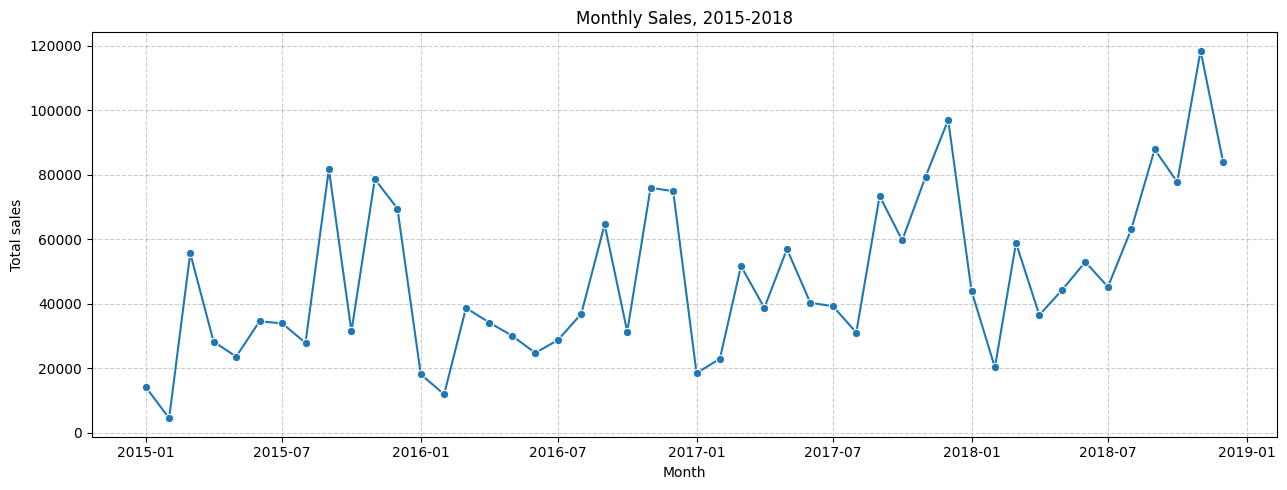

In [100]:
# Chart: monthly sales velocity
plt.figure(figsize=(13, 5))
sns.lineplot(data=monthly, x="Date", y="Total_Sales", marker="o")
plt.grid(color="gray", linestyle="--", alpha=0.4)
plt.title("Monthly Sales, 2015-2018")
plt.xlabel("Month")
plt.ylabel("Total sales")
plt.tight_layout()
plt.savefig("charts/06_monthly_sales.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Total sales for each month from 2015 to 2018.

**What I noticed:** Sales trend upward over the four years, with sharp ups and downs inside each year. The lowest month is February 2015 (about 4.5K) and the highest is November 2018 (about 118K).

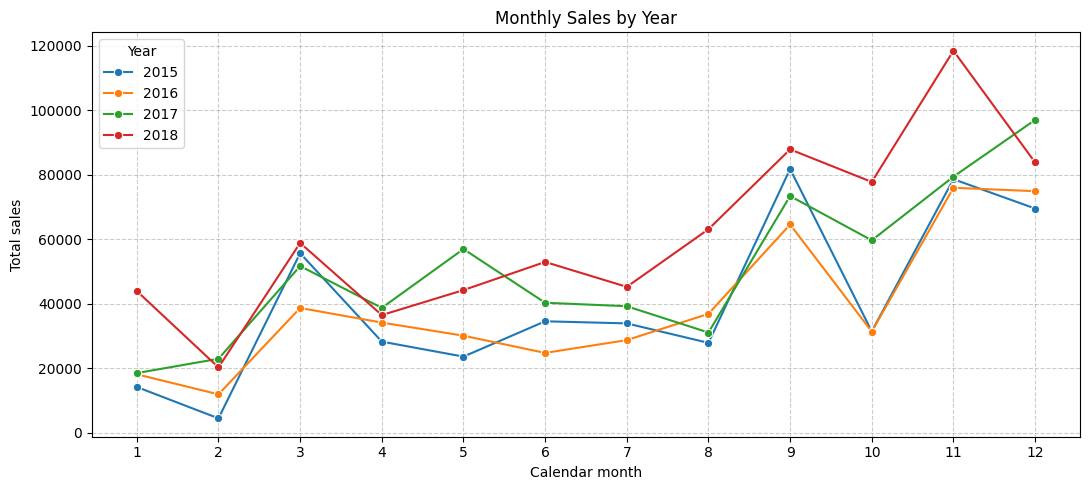

In [101]:
# Chart: one line per year, to see if the pattern repeats
plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly, x="Month", y="Total_Sales", hue="Year", marker="o", palette="tab10")
plt.grid(color="gray", linestyle="--", alpha=0.4)
plt.xticks(range(1, 13))
plt.title("Monthly Sales by Year")
plt.xlabel("Calendar month")
plt.ylabel("Total sales")
plt.tight_layout()
plt.savefig("charts/07_seasonality_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Monthly sales for each year, lined up by calendar month, to check whether the pattern repeats.

**What I noticed:** All four years follow a similar shape: low in January and February, a spike in March, then a climb from August with peaks in September and in November-December. October dips in between. The 2018 line is mostly the highest, which matches the growth seen in the yearly table.

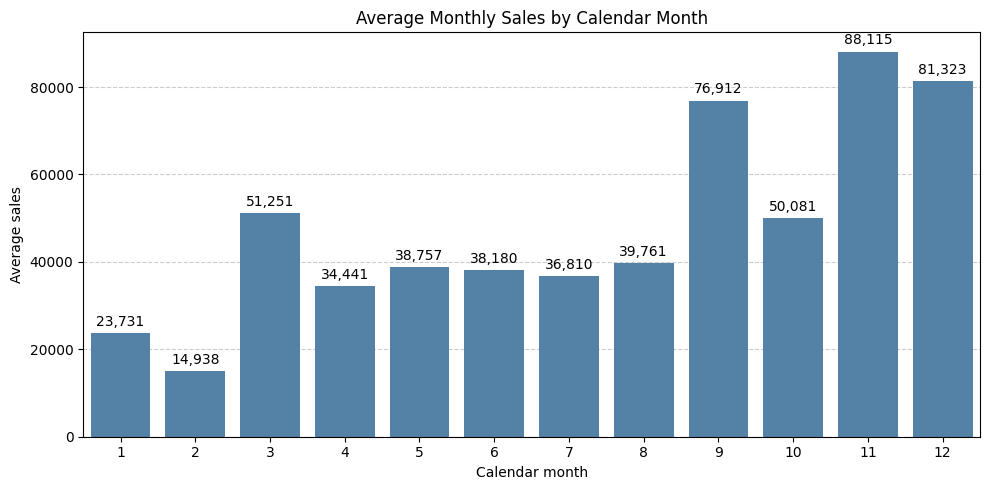

In [102]:
# Chart: average sales for each calendar month
avg_month = monthly.groupby("Month")["Total_Sales"].mean().reset_index()
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=avg_month, x="Month", y="Total_Sales", color="steelblue")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.grid(axis="y", color="gray", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
plt.title("Average Monthly Sales by Calendar Month")
plt.xlabel("Calendar month")
plt.ylabel("Average sales")
plt.tight_layout()
plt.savefig("charts/08_avg_sales_by_calendar_month.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Average total sales for each calendar month, across the four years.

**What I noticed:** November (88,115), December (81,323) and September (76,912) are the strongest months, and together they make up about 43% of a typical year's sales. January (23,731) and February (14,938) are the weakest, at about 7% combined. March (51,251) is a smaller spike.

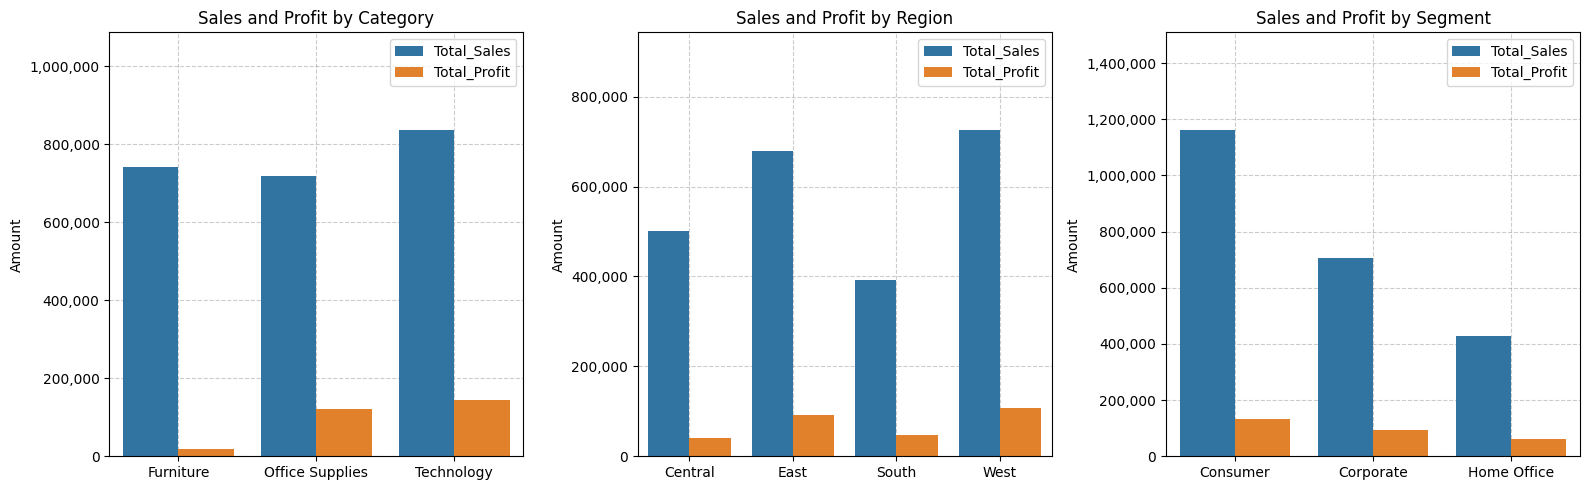

In [103]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
groups = [(cat_summary, "Category"), (reg_summary, "Region"), (seg_summary, "Segment")]

for ax, (data, col) in zip(axes, groups):
    plot_df = data.melt(id_vars=col, value_vars=["Total_Sales", "Total_Profit"],
                        var_name="Measure", value_name="Amount")
    sns.barplot(data=plot_df, x=col, y="Amount", hue="Measure", ax=ax)
    ax.set_title(f"Sales and Profit by {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Amount")
    ax.set_ylim(0, plot_df["Amount"].max() * 1.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
    ax.grid(axis="both", color="gray", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(title="", loc="upper right")

plt.tight_layout()
plt.savefig("charts/09_sales_profit_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

**NOTE**

**What this shows:** Total sales and profit for each Category, Region and Segment.

**What I noticed:** In every group, profit is much smaller than sales. Furniture is the weakest category: sales are close to Technology's, but profit is tiny. Central earns less profit than South despite higher sales. Consumer is the biggest segment, and Home Office has the best margin.

## **EXECUTIVE TACKEAWAYS**


### **Takeaway 1:** Discounts above 20% turn profitable sales into losses

**Observation:** The more discount the company gives, the less profit it makes. Above 20% discount, the company starts losing money.

**Evidence:** Profit margin is 29.5% with no discount and 11.6% at 11-20% discount. Every discount band above 20% has a negative margin, from -10% to -119%. These 1,393 order lines (about 14% of all lines) lost about 135K, while the rest of the business earned about 422K.

**Recommendation:** Set a 20% maximum discount, and require manager approval for anything higher. Start with Machines, Tables and Bookcases. Also track whether sales volume drops after the change, because this data cannot show whether big discounts bring extra customers.



### **Takeaway 2:** Tables and Bookcases lose money, mainly because of heavy discounts

**Observation:** Furniture makes a lot of sales but very little profit, and the loss comes from two products, Tables and Bookcases. Tables are profitable when sold without discount, and the losses start when the discount is high.

**Evidence:** Furniture is about 32% of total sales but only about 6% of total profit. Tables lost 17,725 (margin -8.56%) and Bookcases lost 3,473 (margin -3.02%). Tables with no discount earned +13,276, but the 176 Table lines sold at 30% discount or more lost about 30,698. Chairs (+26,590) and Furnishings (+13,059) are profitable.

**Recommendation:** Limit Table and Bookcase discounts to 20%. Review whether the price of Tables and Bookcases should be raised. If heavy discounts continue, these two products will keep reducing the profit from the rest of Furniture.

### **Takeaway 3:** The biggest customers are not always the most profitable

**Observation:** A customer who buys a lot does not always make money for the company. Some of the largest customers are unprofitable, and about 1 in 5 customers loses money.

**Evidence:** Sean Miller is the top customer by sales (25,043) but has a profit of -1,981. Almost all of his loss comes from Machines (23,460 sales, -1,828 profit, average discount 50%). Overall, 155 customers (19.5%) lose money, with a total loss of 71,224. That is about 25% of the company's total profit. Sales do not depend on a few buyers: the top 10% of customers give only 30.6% of sales.

**Recommendation:** Judge key customers by profit as well as sales. Review the discount terms of loss-making customers, starting with large accounts like Sean Miller, and especially on Machines.

### **Takeaway 4:** Sales peak in September, November and December

**Observation:** Sales follow the same seasonal pattern every year, with a strong second half and a weak start of the year.

**Evidence:** Average monthly sales are highest in November (88,115), December (81,323) and September (76,912). Together these three months give about 43% of a typical year's sales. January (23,731) and February (14,938) together give only about 7%. The same shape appears in all four years from 2015 to 2018, and March is also a smaller spike (51,251).

**Recommendation:** Plan stock, staff and marketing before September and before the November-December period. Use the slow months of January and February for clearance sales and for planning. The reason for the peaks is not in this data, so test it, for example by checking which products sell in those months.

### **Takeaway 5:** Sales are growing faster than profit

**Observation:** The company is growing, but profit is not growing as fast as sales, so the business is becoming a little less efficient.

**Evidence:** Sales grew 29.5% in 2017 and 20.4% in 2018 (from 484K in 2015 to 733K in 2018). In 2018, profit grew only 14.2%, and the profit margin fell from 13.43% in 2017 to 12.74% in 2018.

**Recommendation:** Watch profit margin together with sales every year. The discount findings in Takeaways 1 and 2 are one likely area to look at first, though this data cannot prove it is the cause.

### **Takeaway 6 (bonus):** Central region earns the least from its sales

**Observation:** The Central region sells more than the South but earns less profit from it.

**Evidence:** Central has sales of 501K but profit of only 39.7K, a margin of 7.92%. South has lower sales (392K) but higher profit (46.7K) and a margin of 11.93%. West has the best margin at 14.94%.

**Recommendation:** Look at what is different in Central, such as its discount levels and product mix, compared with the West and the South.

## **Limitations and Next Steps**

**Limitations**
- The data has no cost column, so we can see that heavy discounts and losses go together, but we cannot prove that discounts cause the losses.
- The data covers only 2015-2018, so the seasonal pattern is based on four years.
- The data does not explain why customers get discounts or why some months are strong, so the explanations in this notebook are possible reasons, not proven facts.
- The Returns table was not included in the profit analysis.

**Next steps**
- Analyze return rates by category using the Returns table.
- Test the effect of a 20% discount cap on sales volume.
- Compare discount levels across regions to explain the weak margin in Central.

**Integrity-check**

In [104]:
assert orders.shape == (9994, 25), "Unexpected shape"
assert orders.isnull().sum().sum() == 0, "Missing values remain"
assert orders.duplicated().sum() == 0, "Duplicates remain"
assert orders["Year-Month"].nunique() == 48, "Expected 48 months"
assert round(orders["Sales"].sum()) == 2297201, "Total sales changed"
assert round(orders["Profit"].sum()) == 286397, "Total profit changed"
print("All checks passed")

All checks passed
